# Analyzing Tessera Embeddings with GeoAI & Leafmap

In this notebook, we download and analyze 128-band TESSERA foundation model embeddings across two different years using `geoai` and `geotessera`.
We calculate cosine similarity across all embedding dimensions to detect land cover changes, disturbances, and surface dynamics.

### Workflow Outline:
1. Install and import dependencies (`geoai-py`, `geotessera`, `leafmap`, `rasterio`)
2. Check available TESSERA years and verify tile coverage
3. Define or interactively draw a Region of Interest (ROI)
4. Download multi-band TESSERA GeoTIFFs for two target years
5. Calculate pixel-wise cosine similarity and threshold change outliers
6. Visualize embedding composites and change maps interactively

In [1]:
%pip install -q "geoai-py" "geotessera" "leafmap[maplibre]" rasterio matplotlib numpy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import leafmap.maplibregl as leafmap
from maplibre.plugins import MapboxDrawControls, MapboxDrawOptions
import geoai

# Verify available TESSERA years
available_years = geoai.tessera_available_years()
print(f"Available TESSERA years: {available_years}")

Available TESSERA years: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [4]:
# Draw an ROI or use the map below
m = leafmap.Map(center=[4.5, 51.0], zoom=10, style="positron")
m.add_draw_control(position="top-left")
draw_options = MapboxDrawOptions(
    display_controls_default=False,
    controls=MapboxDrawControls(polygon=True, line_string=False, point=False, trash=True),
)
m.add_draw_control(draw_options)
print("Draw a polygon on the map below. If left empty, a default bounding box in Flanders will be used.")
m

Draw a polygon on the map below. If left empty, a default bounding box in Flanders will be used.


AttributeError: module 'ipyvuetify' has no attribute 'ExpansionPanelHeader'

In [5]:
# Extract bbox (min_lon, min_lat, max_lon, max_lat)
if getattr(m, 'draw_features_selected', None) and len(m.draw_features_selected) > 0:
    geom = m.draw_features_selected[0]['geometry']
    coords = geom['coordinates'][0]
    lons = [c[0] for c in coords]
    lats = [c[1] for c in coords]
    bbox = (min(lons), min(lats), max(lons), max(lats))
else:
    # Default fallback ROI (~10-20km area in Flanders)
    bbox = (4.45, 51.05, 4.60, 51.15)

print(f"Using Bounding Box: {bbox}")

# Check tile count for comparison years
year1 = 2020
year2 = 2024

count_y1 = geoai.tessera_tile_count(bbox=bbox, year=year1)
count_y2 = geoai.tessera_tile_count(bbox=bbox, year=year2)
print(f"Tiles available for {year1}: {count_y1}")
print(f"Tiles available for {year2}: {count_y2}")

Using Bounding Box: (4.291830508300336, 50.98282858035088, 4.354779588148972, 51.020345161894454)
Tiles available for 2020: 4
Tiles available for 2024: 4


In [6]:
dir_y1 = f"./tessera_{year1}"
dir_y2 = f"./tessera_{year2}"

# Download full 128-band GeoTIFFs for both years
print(f"Downloading TESSERA embeddings for {year1}...")
files_y1 = geoai.tessera_download(bbox=bbox, year=year1, output_dir=dir_y1, output_format="tiff")

print(f"Downloading TESSERA embeddings for {year2}...")
files_y2 = geoai.tessera_download(bbox=bbox, year=year2, output_dir=dir_y2, output_format="tiff")

print(f"Downloaded {len(files_y1)} tiles for {year1} and {len(files_y2)} tiles for {year2}.")

Downloaded 4 tiles for 2020 and 4 tiles for 2024.


In [7]:
# Load first pair of overlapping tiles to compute cosine similarity
raster_y1_path = files_y1[0]
# Find corresponding tile in year 2 (by matching filename or using first tile)
filename_target = os.path.basename(raster_y1_path).replace(str(year1), str(year2))
raster_y2_path = os.path.join(dir_y2, filename_target)
if not os.path.exists(raster_y2_path):
    raster_y2_path = files_y2[0]

with rasterio.open(raster_y1_path) as src1, rasterio.open(raster_y2_path) as src2:
    meta = src1.meta.copy()

    # Read 128 bands: (C, H, W) -> float32
    arr1 = src1.read().astype(np.float32)
    arr2 = src2.read().astype(np.float32)

# Ensure dimensions match
min_h = min(arr1.shape[1], arr2.shape[1])
min_w = min(arr1.shape[2], arr2.shape[2])
arr1 = arr1[:, :min_h, :min_w]
arr2 = arr2[:, :min_h, :min_w]

# L2 normalization along channel dimension
norm1 = np.linalg.norm(arr1, axis=0, keepdims=True) + 1e-8
norm2 = np.linalg.norm(arr2, axis=0, keepdims=True) + 1e-8

arr1_norm = arr1 / norm1
arr2_norm = arr2 / norm2

# Cosine Similarity: sum of element-wise product of unit vectors
cosine_similarity = np.sum(arr1_norm * arr2_norm, axis=0)

# Threshold Outliers
# Lower similarity represents stronger change
mild_change = ((cosine_similarity >= 0.2) & (cosine_similarity < 0.6)).astype(np.uint8)
strong_change = (cosine_similarity < 0.2).astype(np.uint8)

# Save outputs as GeoTIFF
out_meta = meta.copy()
out_meta.update({
    'count': 1,
    'dtype': 'float32',
    'height': min_h,
    'width': min_w
})

sim_tif = "tessera_cosine_similarity.tif"
with rasterio.open(sim_tif, 'w', **out_meta) as dst:
    dst.write(cosine_similarity, 1)

print(f"Similarity computed. Mean: {cosine_similarity.mean():.4f}, Min: {cosine_similarity.min():.4f}, Max: {cosine_similarity.max():.4f}")

Similarity computed. Mean: 0.7360, Min: 0.1093, Max: 0.9839


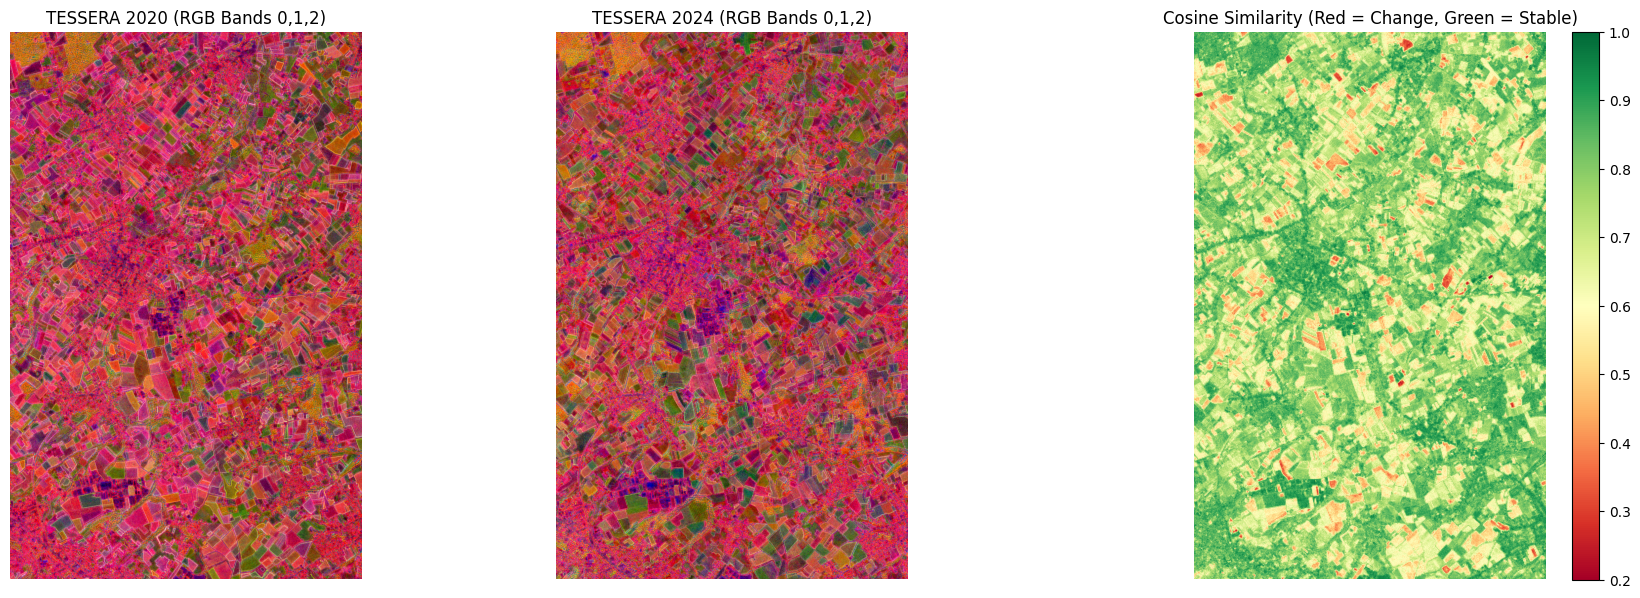

In [8]:
# Static Plot: False Color RGB (Bands 0, 1, 2) and Cosine Similarity
def normalize_rgb(img_rgb):
    p2, p98 = np.percentile(img_rgb, (2, 98))
    return np.clip((img_rgb - p2) / (p98 - p2 + 1e-8), 0, 1)

rgb_y1 = np.transpose(arr1[:3], (1, 2, 0))
rgb_y2 = np.transpose(arr2[:3], (1, 2, 0))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(normalize_rgb(rgb_y1))
axes[0].set_title(f"TESSERA {year1} (RGB Bands 0,1,2)")
axes[0].axis('off')

axes[1].imshow(normalize_rgb(rgb_y2))
axes[1].set_title(f"TESSERA {year2} (RGB Bands 0,1,2)")
axes[1].axis('off')

im = axes[2].imshow(cosine_similarity, cmap='RdYlGn', vmin=0.2, vmax=1.0)
axes[2].set_title("Cosine Similarity (Red = Change, Green = Stable)")
axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [15]:
from google.colab import output
output.enable_custom_widget_manager()

In [18]:
# Interactieve Leafmap Tile Viewer met foutafhandeling voor localtileserver
import leafmap

view_map = leafmap.Map()

try:
    # Probeer het raster interactief toe te voegen
    view_map.add_raster(sim_tif, colormap="RdYlGn", layer_name="Cosine Similarity", vmin=0.2, vmax=1.0)
    print("Raster succesvol interactief geladen!")
except Exception as e:
    print("De interactieve raster-server (localtileserver) gaf een foutmelding.")
    print("Gebruik de statische visualisatie hierboven in de 'visualize_results' cel om de resultaten te bekijken.")
    print(f"Foutdetails: {e}")

view_map

De interactieve raster-server (localtileserver) gaf een foutmelding.
Gebruik de statische visualisatie hierboven in de 'visualize_results' cel om de resultaten te bekijken.
Foutdetails: 500 Server Error: Internal Server Error for url: http://127.0.0.1:33063/api/metadata?&filename=%2Fcontent%2Ftessera_cosine_similarity.tif


Map(center=[20, 0], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_out_text…

Support for third party widgets will remain active for the duration of the session. To disable support:

In [19]:
from google.colab import output
output.disable_custom_widget_manager()